# 1. Model Check

## 1.1 Loading CLIP
We load OpenAI's CLIP ViT-B/32 model with open_clip.
- `model`: image and text encoders
- `preprocess`: transform that resizes and normalizes an image the way the model expects
- `tokenizer`: function that converts text into tokens the model can read
The model runs on the Mac GPU (MPS).

Note: OpenAI's CLIP weights were trained with the QuickGELU activation, so we use the `ViT-B-32-quickgelu` config to match them.

In [2]:
import torch
import open_clip

device = "mps" if torch.backends.mps.is_available() else "cpu"

clip_model, _, clip_preprocess = open_clip.create_model_and_transforms("ViT-B-32-quickgelu", pretrained="openai")
clip_tokenizer = open_clip.get_tokenizer("ViT-B-32-quickgelu")
clip_model = clip_model.to(device).eval()

n_params = sum(p.numel() for p in clip_model.parameters())
print("Device:", device)
print("CLIP parameters:", round(n_params / 1e6, 1), "M")

Device: mps
CLIP parameters: 151.3 M


## 1.2 Loading RemoteCLIP
RemoteCLIP weights are downloaded from the Hugging Face Hub (`chendelong/RemoteCLIP`).
We create an empty ViT-B/32 model with open_clip and load the RemoteCLIP weights into it.
We follow the authors' README and use the `ViT-B-32` config, so our numbers can be compared with the paper.
Checkpoints are stored in `cache/`, which is ignored by git.

In [3]:
from huggingface_hub import hf_hub_download

ckpt_path = hf_hub_download("chendelong/RemoteCLIP", "RemoteCLIP-ViT-B-32.pt", cache_dir="../cache/checkpoints")

rclip_model, _, rclip_preprocess = open_clip.create_model_and_transforms("ViT-B-32")
rclip_tokenizer = open_clip.get_tokenizer("ViT-B-32")

state_dict = torch.load(ckpt_path, map_location="cpu")
print(rclip_model.load_state_dict(state_dict))

rclip_model = rclip_model.to(device).eval()

No pretrained weights loaded for model 'ViT-B-32'. Model initialized randomly.


<All keys matched successfully>


## 1.3 Loading a sample from RESISC45
NWPU-RESISC45 is a scene classification dataset with 45 classes. We load its test split from the Hugging Face Hub (`timm/resisc45`) and take one image to use in the sanity check.
RemoteCLIP reports zero-shot results on this dataset, so we will later use it to verify our setup.
The dataset is stored in `cache/`, which is ignored by git.

Generating test split: 100%|██████████| 6300/6300 [00:00<00:00, 113996.30 examples/s]


6300 test images, 45 classes


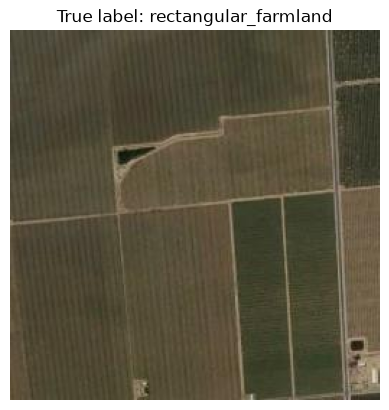

In [5]:
from datasets import load_dataset
import matplotlib.pyplot as plt

resisc = load_dataset("timm/resisc45", split="test", cache_dir="../cache/datasets")
label_names = resisc.features["label"].names
print(len(resisc), "test images,", len(label_names), "classes")

sample = resisc[0]
plt.imshow(sample["image"])
plt.title("True label: " + label_names[sample["label"]])
plt.axis("off")
plt.show()

## 1.4 Zero-shot sanity check on a single image
We compare the sample image with all 45 RESISC45 class names using both models.
Class names contain underscores (e.g. `rectangular_farmland`), so we replace them with spaces before building the prompts.
For each model:
1. The image is encoded into an image embedding and each prompt into a text embedding.
2. Both are L2-normalized, so their dot product is the cosine similarity.
3. Similarities are multiplied by 100 (CLIP's logit scale) and passed through softmax to get probabilities.
We plot the top-5 predictions of each model next to the image.

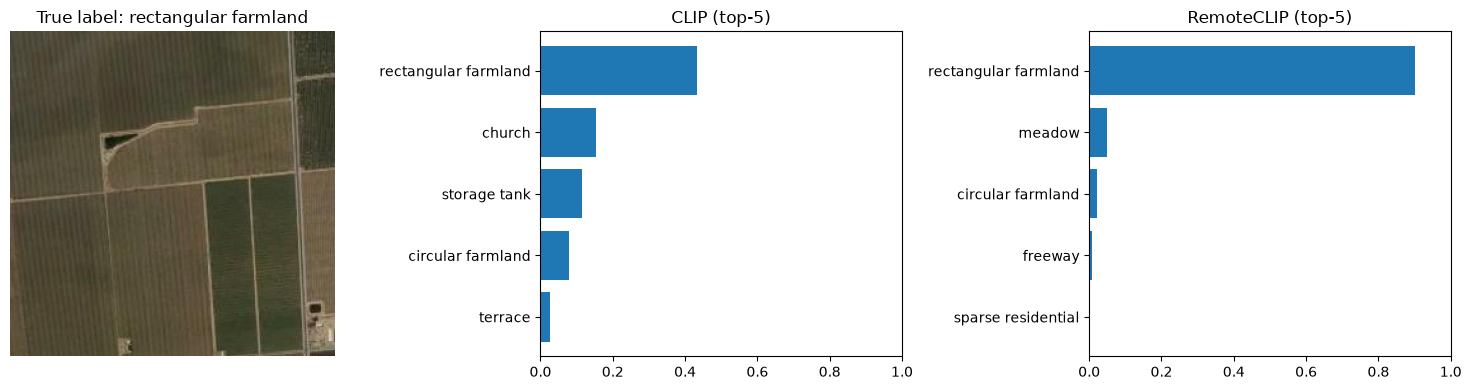

In [6]:
import numpy as np

class_names = [name.replace("_", " ") for name in label_names]
template = "a satellite photo of {}."

def zero_shot_probs(model, preprocess, tokenizer, image):
    image_input = preprocess(image).unsqueeze(0).to(device)
    text_input = tokenizer([template.format(c) for c in class_names]).to(device)
    with torch.no_grad():
        image_emb = model.encode_image(image_input)
        text_emb = model.encode_text(text_input)
    image_emb = image_emb / image_emb.norm(dim=-1, keepdim=True)
    text_emb = text_emb / text_emb.norm(dim=-1, keepdim=True)
    probs = (100 * image_emb @ text_emb.T).softmax(dim=-1)
    return probs[0].cpu().numpy()

image = sample["image"].convert("RGB")
results = {
    "CLIP": zero_shot_probs(clip_model, clip_preprocess, clip_tokenizer, image),
    "RemoteCLIP": zero_shot_probs(rclip_model, rclip_preprocess, rclip_tokenizer, image),
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(image)
axes[0].set_title("True label: " + class_names[sample["label"]])
axes[0].axis("off")
for ax, (model_name, probs) in zip(axes[1:], results.items()):
    top5 = np.argsort(probs)[::-1][:5]
    ax.barh([class_names[i] for i in top5][::-1], probs[top5][::-1])
    ax.set_title(model_name + " (top-5)")
    ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()

## 1.5 Zero-shot accuracy on the full RESISC45 test split
To verify our setup, we try to reproduce the zero-shot numbers reported in the RemoteCLIP paper (ViT-B-32 on RESISC45: CLIP 60.92%, RemoteCLIP 70.33%).
1. All test images are encoded in batches; embeddings are L2-normalized.
2. The 45 prompts are encoded once per model.
3. The prediction for each image is the class with the highest cosine similarity.
Image embeddings are saved to `cache/` so they do not need to be recomputed.
Note: the paper's exact split may differ from ours, so we expect close but not identical numbers.